<h1 style="
    background-color: darkblue;
    color: white;
    text-align: center;
    padding: 20px;
    border-radius: 10px;
    font-size: 28px;
">
    Module End Assignment : Data Analysis
</h1>

In [22]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly .express as px
import plotly . io as pio


In [23]:
df = pd.read_csv("social_media_engagement_5000.csv")

In [24]:
print(df.shape)

(5000, 19)


In [25]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


### Data Cleaning

In [29]:
# 1) clean column names (keep underscores)
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^0-9a-z_]+", "", regex=True))

# 2) rename to the standard names (skips any that are already renamed)
df = df.rename(columns={
    "userid": "user_id",
    "postid": "post_id",
    "posttype": "post_type",
    "watchtimesec": "watch_time",
    "watchtime": "watch_time",
    "impressioncount": "impressions",
    "postedat": "date",
    "followercount": "followers",
    "isverified": "verified",
    "engagementrate": "engagement_rate",
})

# 3) convert types
df["date"] = pd.to_datetime(df["date"], errors="coerce")
for c in ["likes", "comments", "shares", "impressions", "watch_time",
          "engagement_rate", "followers", "age"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print(df.columns.tolist())

KeyError: 'date'

In [ ]:
likes = df["likes"].to_numpy(dtype=float)
print(likes.shape, np.nanmean(likes), np.nanmedian(likes), np.nanstd(likes))
print(np.nanmax(likes), np.nanargmax(likes), np.nanpercentile(likes, 90))

scaled = (likes - np.nanmin(likes)) / (np.nanmax(likes) - np.nanmin(likes))   # min-max scaling
flag = np.where(likes > np.nanpercentile(likes, 90), "High", "Normal")        # top 10 %
print(dict(zip(*np.unique(flag, return_counts=True))))

interactions = np.column_stack([df["likes"], df["comments"], df["shares"]]).astype(float)
print(np.nansum(interactions, axis=1)[:5])         # total interactions per post

(5000,) 10107.043711340206 10105.5 5789.222332204695
19998.0 3985 18076.1
{np.str_('High'): np.int64(485), np.str_('Normal'): np.int64(4515)}
[ 8522. 16163.  6161.  7482. 16717.]


In [ ]:
missing = pd.DataFrame({"missing_count": df.isnull().sum(),
                        "missing_pct": (df.isna().mean()*100).round(2)})
missing[missing["missing_count"] > 0]

,missing_count,missing_pct
age,150,3.0
gender,150,3.0
likes,150,3.0
comments,150,3.0
shares,150,3.0
sentiment,150,3.0


In [ ]:
print(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

0


In [ ]:
needed = ["date", "impressions", "followers", "engagement_rate", "likes", "comments", "shares", "watch_time", "age"]
print("Missing:", [c for c in needed if c not in df.columns])

Missing: ['date', 'impressions', 'followers', 'watch_time']


In [ ]:
df = df.rename(columns={
    "postedat": "date", "impressioncount": "impressions",
    "followercount": "followers", "engagementrate": "engagement_rate",
    "postid": "post_id", "userid": "user_id",
})
df["date"] = pd.to_datetime(df["date"], errors="coerce")

KeyError: 'date'

In [ ]:
df["hashtag_count"] = df["hashtags"].fillna("").apply(
    lambda x: len(re.findall(r"#\w+", x)) or len([t for t in re.split(r"[,;|\s]+", x) if t]))

def clean_sentiment(x):
    s = re.sub(r"[^a-z]", "", str(x).lower())
    if s.startswith("pos"): return "Positive"
    if s.startswith("neg"): return "Negative"
    if s.startswith("neu"): return "Neutral"
    return np.nan
df["sentiment"] = df["sentiment"].apply(clean_sentiment)
df["sentiment"] = df["sentiment"].fillna(df["sentiment"].mode().iloc[0])

NameError: name 're' is not defined

### Data Exploration

In [ ]:
print(df.shape)
print(list(df.columns))
df.head()
df.tail()

(4991, 36)
['userid', 'age', 'gender', 'country', 'postid', 'posttype', 'category', 'likes', 'comments', 'shares', 'watchtime', 'impressions', 'date', 'followers', 'verified', 'device', 'sentiment', 'hashtags', 'engagementrate', 'hashtagcount', 'engagementscore', 'totalinteractions', 'loglikes', 'logcomments', 'logshares', 'logimpressions', 'logfollowers', 'hourofday', 'timeofday', 'agegroup', 'verifiedlabel', 'countryavgimpressionsx', 'countryavgerx', 'countryavgimpressionsy', 'countryavgery', 'hashtag_count']


,userid,age,gender,country,postid,posttype,category,likes,comments,shares,...,logfollowers,hourofday,timeofday,agegroup,verifiedlabel,countryavgimpressionsx,countryavgerx,countryavgimpressionsy,countryavgery,hashtag_count
4986,52604,59.0,Female,Canada,608594,Video,Tech,1049.0,751.0,1046.0,...,13.527334,0,Night (0-5),55+,Not Verified,48656.490234,0.918060,48656.490234,0.918060,3
4987,43933,31.0,Male,Australia,247089,Video,Fitness,15252.0,177.0,836.0,...,13.554144,0,Night (0-5),25-34,Not Verified,48346.383367,1.324339,48346.383367,1.324339,1
4988,33793,44.0,Female,Germany,530898,Video,Food,345.0,1164.0,334.0,...,13.411428,0,Night (0-5),35-44,Not Verified,48683.887526,0.756298,48683.887526,0.756298,1
4989,87275,27.0,Female,Germany,875299,Image,Fitness,12378.0,2613.0,1138.0,...,12.529818,0,Night (0-5),25-34,Verified,48683.887526,0.756298,48683.887526,0.756298,1
4990,86367,52.0,Other,Uae,601817,Reel,Fitness,10486.0,774.0,628.0,...,12.871666,0,Night (0-5),45-54,Not Verified,48935.631474,1.114099,48935.631474,1.114099,3


In [ ]:
df.info()
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [ ]:
# Select numerical columns
numeric_columns = df.select_dtypes(include="number").columns

# Mean
df[numeric_columns].mean()

# Median
df[numeric_columns].median()

# Mode
df[numeric_columns].mode()

# Standard Deviation
df[numeric_columns].std()

user_id              26090.370121
age                     14.912381
post_id             260646.957267
likes                 5789.819252
comments               869.537889
shares                 579.615158
watch_time_sec        2308.096459
impression_count     28844.939104
follower_count      230927.884535
engagement_rate          5.318029
dtype: float64

In [ ]:
likes = df["likes"].to_numpy(dtype=float)
print(likes.shape, np.nanmean(likes), np.nanmedian(likes), np.nanstd(likes))
print(np.nanmax(likes), np.nanargmax(likes), np.nanpercentile(likes, 90))

scaled = (likes - np.nanmin(likes)) / (np.nanmax(likes) - np.nanmin(likes))   # min-max scaling
flag = np.where(likes > np.nanpercentile(likes, 90), "High", "Normal")        # top 10 %
print(dict(zip(*np.unique(flag, return_counts=True))))

interactions = np.column_stack([df["likes"], df["comments"], df["shares"]]).astype(float)
print(np.nansum(interactions, axis=1)[:5])         # total interactions per post

(5000,) 10107.043711340206 10105.5 5789.222332204695
19998.0 3985 18076.1
{np.str_('High'): np.int64(485), np.str_('Normal'): np.int64(4515)}
[ 8522. 16163.  6161.  7482. 16717.]


In [ ]:
missing = pd.DataFrame({"missing_count": df.isnull().sum(),
                        "missing_pct": (df.isna().mean()*100).round(2)})
missing[missing["missing_count"] > 0]

,missing_count,missing_pct
age,150,3.0
gender,150,3.0
likes,150,3.0
comments,150,3.0
shares,150,3.0
sentiment,150,3.0


In [ ]:
print(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

0


In [ ]:
print(df.columns.tolist())
df.head(3)

['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345


In [ ]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^0-9a-z]+", "", regex=True).str.strip(""))

for c in ["post_type", "category", "device", "country"]:
    if c in df.columns:
        df[c] = df[c].astype(str).str.strip().str.title()
    else:
        print("Column not found:", c)

Column not found: post_type
Column not found: category
Column not found: device


In [ ]:
df = df.rename(columns={"content_category": "category"})

In [ ]:
guess = {
    "post_type": ["post_type", "content_type", "media_type", "type", "format"],
    "category":  ["category", "content_category", "topic", "niche"],
    "device":    ["device", "device_type", "platform", "source"],
}
for std, options in guess.items():
    found = next((c for o in options for c in df.columns if o in c), None)
    print(std, "->", found)
    if found and found != std:
        df = df.rename(columns={found: std})

post_type -> posttype
category -> postcategory
device -> devicetype


In [ ]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^0-9a-z]+", "", regex=True).str.strip(""))
print("Your columns:", df.columns.tolist())

guess = {
    "date":        ["date", "post_date", "timestamp", "posted_at", "created_at", "post_time"],
    "post_type":   ["post_type", "content_type", "media_type", "format", "type"],
    "category":    ["category", "content_category", "topic", "niche"],
    "device":      ["device", "device_type", "platform", "source"],
    "country":     ["country", "location", "region"],
    "gender":      ["gender", "sex"],
    "age":         ["age", "user_age"],
    "followers":   ["followers", "follower_count"],
    "impressions": ["impressions", "views", "reach"],
    "watch_time":  ["watch_time", "watch"],
    "sentiment":   ["sentiment"],
    "verified":    ["verified"],
    "hashtags":    ["hashtags", "hashtag"],
}
for std, options in guess.items():
    found = next((c for o in options for c in df.columns if o in c), None)
    print(f"{std:12s} -> {found}")
    if found and found != std:
        df = df.rename(columns={found: std})

Your columns: ['userid', 'age', 'gender', 'country', 'postid', 'posttype', 'category', 'likes', 'comments', 'shares', 'watchtimesec', 'impressioncount', 'postedat', 'followercount', 'isverified', 'device', 'sentiment', 'hashtags', 'engagementrate']
date         -> None
post_type    -> posttype
category     -> category
device       -> device
country      -> country
gender       -> gender
age          -> age
followers    -> None
impressions  -> None
watch_time   -> watchtimesec
sentiment    -> sentiment
verified     -> isverified
hashtags     -> hashtags


In [ ]:
print(df.columns.tolist())

['userid', 'age', 'gender', 'country', 'postid', 'post_type', 'category', 'likes', 'comments', 'shares', 'watch_time', 'impressioncount', 'postedat', 'followercount', 'verified', 'device', 'sentiment', 'hashtags', 'engagementrate']


In [ ]:
for c in df.columns:
    print(c)

userid
age
gender
country
postid
post_type
category
likes
comments
shares
watch_time
impressioncount
postedat
followercount
verified
device
sentiment
hashtags
engagementrate


In [ ]:
df = df.rename(columns={
    "postedat": "date",
    "impressioncount": "impressions",
    "followercount": "followers",
    "engagementrate": "engagement_rate",
    "postid": "post_id",
    "userid": "user_id",
})

df["date"] = pd.to_datetime(df["date"], errors="coerce")   # make date a real date column

print(df.columns.tolist())

['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'category', 'likes', 'comments', 'shares', 'watch_time', 'impressions', 'date', 'followers', 'verified', 'device', 'sentiment', 'hashtags', 'engagement_rate']


C:\Users\PC\AppData\Local\Temp\ipykernel_5692\3079459113.py:10: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["date"] = pd.to_datetime(df["date"], errors="coerce")   # make date a real date column


In [ ]:
df = df.dropna(how="all")                                   # fully empty rows
df = df.sort_values("date").reset_index(drop=True)
df["date"] = df["date"].ffill().bfill()                     # forward / backward fill

for c in ["likes","comments","shares","impressions","watch_time","followers","age"]:
    df[c] = df[c].fillna(df[c].median())                    # median for numbers
for c in ["gender","country","post_type","category","sentiment","device"]:
    df[c] = df[c].fillna(df[c].mode().iloc[0])              # mode for categories

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
if "post_id" in df.columns:
    df = df.drop_duplicates(subset="post_id", keep="first").reset_index(drop=True)
print("Rows left:", len(df))

Duplicate rows: 0
Rows left: 4991


In [ ]:
import re
def std_gender(x):
    if pd.isna(x): return np.nan
    s = str(x).strip().lower()
    if s in {"m","male","man"}: return "Male"
    if s in {"f","female","woman"}: return "Female"
    return "Other"
df["gender"] = df["gender"].apply(std_gender)

for c in ["post_type","category","device","country"]:
    df[c] = df[c].astype(str).str.strip().str.title()      # trim spaces, fix case

for c in ["likes","comments","shares","impressions","followers","watch_time"]:
    df.loc[df[c] < 0, c] = np.nan                           # negatives are impossible
df.loc[(df["age"] < 13) | (df["age"] > 100), "age"] = np.nan

for c in ["likes","comments","shares"]:                      # cap extreme outliers
    q1, q3 = df[c].quantile([.25,.75])
    cap = max(q3 + 3*(q3-q1), df[c].quantile(.99))
    df[c] = df[c].clip(upper=cap)

In [ ]:
import re

def std_text(x):
    if pd.isna(x): return np.nan
    s = re.sub(r"\s+", " ", str(x)).strip()
    return np.nan if s.lower() in {"", "nan", "none", "null", "na", "n/a", "unknown"} else s.title()

for c in ["post_type", "category", "device", "country"]:
    df[c] = df[c].apply(std_text)
df["device"] = df["device"].replace({"Ios": "iOS"})

def std_gender(x):
    if pd.isna(x): return np.nan
    s = str(x).strip().lower()
    if s in {"m", "male", "man"}: return "Male"
    if s in {"f", "female", "woman"}: return "Female"
    if s in {"", "nan", "none", "unknown"}: return np.nan
    return "Other"
df["gender"] = df["gender"].apply(std_gender)

# verified -> True / False
vmap = {"true": True, "yes": True, "y": True, "1": True, "1.0": True,
        "false": False, "no": False, "n": False, "0": False, "0.0": False}
df["verified"] = df["verified"].astype(str).str.strip().str.lower().map(vmap)

# make number columns numeric
NUM = ["likes", "comments", "shares", "impressions", "followers", "watch_time", "engagement_rate", "age"]
for c in NUM:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# unrealistic values -> missing (filled in the next cell)
for c in ["likes", "comments", "shares", "impressions", "followers", "watch_time"]:
    df.loc[df[c] < 0, c] = np.nan
df.loc[(df["age"] < 13) | (df["age"] > 100), "age"] = np.nan
df.loc[df["engagement_rate"] < 0, "engagement_rate"] = np.nan

# cap extreme outliers in likes, comments, shares
for c in ["likes", "comments", "shares"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    cap = max(q3 + 3 * (q3 - q1), df[c].quantile(0.99))
    df[c] = df[c].clip(upper=cap)

print(df["gender"].value_counts(dropna=False))


gender
Male      1844
Other     1578
Female    1569
Name: count, dtype: int64


In [ ]:
df = df.dropna(how="all")
df = df.sort_values("date").reset_index(drop=True)
df["date"] = df["date"].ffill().bfill()                 # forward / backward fill

for c in NUM:                                           # numbers -> median
    df[c] = df[c].fillna(df[c].median())

for c in ["gender", "country", "post_type", "category", "sentiment", "device", "verified"]:
    df[c] = df[c].fillna(df[c].mode().iloc[0])          # categories -> mode
df["verified"] = df["verified"].astype(bool)

print("Missing values left:\n", df.isna().sum())

Missing values left:
 user_id            0
age                0
gender             0
country            0
post_id            0
post_type          0
category           0
likes              0
comments           0
shares             0
watch_time         0
impressions        0
date               0
followers          0
verified           0
device             0
sentiment          0
hashtags           0
engagement_rate    0
dtype: int64


In [ ]:
def count_tags(x):
    x = "" if pd.isna(x) else str(x)
    tags = re.findall(r"#\w+", x)
    if not tags:
        tags = [t for t in re.split(r"[,;|\s]+", x) if t]
    return len(tags)
df["hashtag_count"] = df["hashtags"].apply(count_tags)

def clean_sentiment(x):
    if pd.isna(x): return np.nan
    s = re.sub(r"[^a-z]", "", str(x).lower())
    if s.startswith("pos"): return "Positive"
    if s.startswith("neg"): return "Negative"
    if s.startswith("neu"): return "Neutral"
    return np.nan
df["sentiment"] = df["sentiment"].apply(clean_sentiment)
df["sentiment"] = df["sentiment"].fillna(df["sentiment"].mode().iloc[0])

print(df["sentiment"].value_counts())
print(df["hashtag_count"].value_counts().sort_index())

sentiment
Positive    2508
Neutral     1526
Negative     957
Name: count, dtype: int64
hashtag_count
1    1653
2    1693
3    1645
Name: count, dtype: int64


In [ ]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))
display(df.head())
display(df.tail())
df.info()

Shape: (4991, 20)
Columns: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'category', 'likes', 'comments', 'shares', 'watch_time', 'impressions', 'date', 'followers', 'verified', 'device', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


,user_id,age,gender,country,post_id,post_type,category,likes,comments,shares,watch_time,impressions,date,followers,verified,device,sentiment,hashtags,engagement_rate,hashtag_count
0,65745,20.0,Female,Usa,716149,Video,Education,5780.0,1926.0,1536.0,4193.0,11037.0,2022-01-01,2342.0,False,Tablet,Positive,#fun,0.837365,1
1,73232,58.0,Male,Brazil,763662,Video,Lifestyle,10924.0,992.0,1461.0,2174.0,11361.0,2022-01-01,712234.0,False,Tablet,Negative,#fun,1.177449,1
2,16629,50.0,Female,France,916929,Video,Tech,19873.0,243.0,1918.0,6385.0,1334.0,2022-01-01,357021.0,False,Mobile,Neutral,#foodie #reels #love,16.517241,3
3,19446,54.0,Female,India,106028,Reel,Fashion,9723.0,248.0,1817.0,5305.0,92434.0,2022-01-01,626156.0,False,Tablet,Positive,#music,0.127529,1
4,97508,48.0,Male,Australia,155313,Text,Lifestyle,4000.0,2900.0,714.0,1490.0,8166.0,2022-01-01,74642.0,False,Mobile,Negative,#fashion #travel,0.932403,2


,user_id,age,gender,country,post_id,post_type,category,likes,comments,shares,watch_time,impressions,date,followers,verified,device,sentiment,hashtags,engagement_rate,hashtag_count
4986,87275,27.0,Female,Germany,875299,Image,Fitness,12378.0,2613.0,1138.0,3161.0,99489.0,2023-12-31,276458.0,True,Desktop,Positive,#music,0.162118,1
4987,52604,59.0,Female,Canada,608594,Video,Tech,1049.0,751.0,1046.0,1616.0,65636.0,2023-12-31,749628.0,False,Mobile,Positive,#fun #fitness #reels,0.043360,3
4988,10846,64.0,Female,Japan,545278,Text,Fitness,13890.0,2124.0,1543.0,1878.0,12796.0,2023-12-31,34819.0,False,Mobile,Positive,#tech,1.372069,1
4989,43933,31.0,Male,Australia,247089,Video,Fitness,15252.0,177.0,836.0,6567.0,59124.0,2023-12-31,769998.0,False,Desktop,Positive,#love,0.275100,1
4990,86367,52.0,Other,Uae,601817,Reel,Fitness,10486.0,774.0,628.0,1886.0,88021.0,2023-12-31,389128.0,False,Desktop,Neutral,#travel #fashion #tech,0.135059,3


<class 'pandas.DataFrame'>
RangeIndex: 4991 entries, 0 to 4990
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   user_id          4991 non-null   int64         
 1   age              4991 non-null   float64       
 2   gender           4991 non-null   str           
 3   country          4991 non-null   str           
 4   post_id          4991 non-null   int64         
 5   post_type        4991 non-null   str           
 6   category         4991 non-null   str           
 7   likes            4991 non-null   float64       
 8   comments         4991 non-null   float64       
 9   shares           4991 non-null   float64       
 10  watch_time       4991 non-null   float64       
 11  impressions      4991 non-null   float64       
 12  date             4991 non-null   datetime64[us]
 13  followers        4991 non-null   float64       
 14  verified         4991 non-null   bool          
 15

In [ ]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
user_id,4991.0,54557.857744,10055.0,32306.0,54386.0,77172.5,99963.0,26090.941507
age,4991.0,38.442196,13.0,26.0,38.0,51.0,64.0,14.685829
post_id,4991.0,547854.825486,100068.0,322410.0,547905.0,771256.5,999455.0,260657.341322
likes,4991.0,10104.57794,10.0,5224.5,10105.5,14960.0,19998.0,5703.065853
comments,4991.0,1502.158085,0.0,791.0,1497.0,2236.0,2999.0,856.843262
shares,4991.0,1003.60529,0.0,512.0,1012.0,1483.0,1999.0,570.4921
watch_time,4991.0,4015.71649,0.0,2023.5,4034.0,6021.0,7998.0,2306.931416
impressions,4991.0,50008.114406,105.0,24997.0,49926.0,74629.5,99995.0,28838.780135
date,4991,2022-12-28 03:55:08.595471,2022-01-01 00:00:00,2022-07-03 00:00:00,2022-12-27 00:00:00,2023-06-26 00:00:00,2023-12-31 00:00:00,NaN
followers,4991.0,393721.506111,87.0,194464.0,389027.0,589759.5,799533.0,230943.984018


In [ ]:
CATS = ["post_type", "category", "country", "gender", "device", "sentiment", "verified"]
for c in CATS:
    print(f"\n=== {c} | unique values: {df[c].nunique()} ===")
    print(df[c].unique()[:10])
    print(df[c].value_counts())
print(df[CATS].nunique())


=== post_type | unique values: 4 ===
<StringArray>
['Video', 'Reel', 'Text', 'Image']
Length: 4, dtype: str
post_type
Reel     1281
Image    1245
Text     1242
Video    1223
Name: count, dtype: int64

=== category | unique values: 8 ===
<StringArray>
['Education', 'Lifestyle',      'Tech',   'Fashion',     'Music',    'Travel',
   'Fitness',      'Food']
Length: 8, dtype: str
category
Fitness      674
Tech         664
Music        635
Education    631
Lifestyle    604
Travel       600
Food         592
Fashion      591
Name: count, dtype: int64

=== country | unique values: 10 ===
<StringArray>
[      'Usa',    'Brazil',    'France',     'India', 'Australia',   'Germany',
    'Canada',        'Uk',       'Uae',     'Japan']
Length: 10, dtype: str
country
India        535
Canada       512
Brazil       504
Uae          502
Usa          498
France       495
Australia    493
Uk           491
Germany      489
Japan        472
Name: count, dtype: int64

=== gender | unique values: 3 ===
<Str

In [ ]:
NUMS = ["age", "followers", "likes", "comments", "shares",
        "impressions", "watch_time", "engagement_rate", "hashtag_count"]
corr = df[NUMS].corr()
corr

,age,followers,likes,comments,shares,impressions,watch_time,engagement_rate,hashtag_count
age,1.000000,-0.024893,-0.036707,-0.007227,0.013881,0.013981,0.006961,0.007954,0.008099
followers,-0.024893,1.000000,-0.022630,-0.011959,-0.011885,-0.014426,0.002934,0.002218,0.008654
likes,-0.036707,-0.022630,1.000000,-0.018944,0.004791,0.007731,0.008312,0.093545,-0.001903
comments,-0.007227,-0.011959,-0.018944,1.000000,0.005271,-0.009530,-0.017001,0.000042,-0.015558
shares,0.013881,-0.011885,0.004791,0.005271,1.000000,-0.004274,0.012998,0.021597,0.012608
impressions,0.013981,-0.014426,0.007731,-0.009530,-0.004274,1.000000,-0.004373,-0.232285,-0.003238
watch_time,0.006961,0.002934,0.008312,-0.017001,0.012998,-0.004373,1.000000,-0.001218,-0.024451
engagement_rate,0.007954,0.002218,0.093545,0.000042,0.021597,-0.232285,-0.001218,1.000000,0.005420
hashtag_count,0.008099,0.008654,-0.001903,-0.015558,0.012608,-0.003238,-0.024451,0.005420,1.000000


In [ ]:
print("Average likes by post type")
display(df.groupby("post_type")["likes"].mean().sort_values(ascending=False).to_frame("avg_likes"))

print("Average impressions by country")
display(df.groupby("country")["impressions"].mean().sort_values(ascending=False).to_frame("avg_impressions"))

Average likes by post type


,avg_likes
post_type,
Video,10178.528209
Image,10103.034940
Text,10100.520531
Reel,10039.409446


Average impressions by country


,avg_impressions
country,
India,52462.386916
France,51719.292929
Usa,51193.267068
Uk,51113.342159
Japan,49616.135593
Brazil,49193.174603
Uae,48935.631474
Germany,48683.887526
Canada,48656.490234


In [ ]:
 # weighted interaction score
df["engagement_score"] = df["likes"] + 2 * df["comments"] + 3 * df["shares"]
df["total_interactions"] = df["likes"] + df["comments"] + df["shares"]

# log-transformed metrics
for c in ["likes", "comments", "shares", "impressions", "followers"]:
    df[f"log_{c}"] = np.log1p(df[c])

# helper columns used later for charts and insights
df["hour_of_day"] = df["date"].dt.hour
df["time_of_day"] = pd.cut(df["hour_of_day"], bins=[-1, 5, 11, 16, 20, 23],
                           labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-16)",
                                   "Evening (17-20)", "Late Night (21-23)"])
df["age_group"] = pd.cut(df["age"], bins=[12, 17, 24, 34, 44, 54, 100],
                         labels=["13-17", "18-24", "25-34", "35-44", "45-54", "55+"])
df["verified_label"] = np.where(df["verified"], "Verified", "Not Verified")

df[["likes", "comments", "shares", "engagement_score", "hashtag_count", "log_likes"]].head()


,likes,comments,shares,engagement_score,hashtag_count,log_likes
0,5780.0,1926.0,1536.0,14240.0,1,8.662332
1,10924.0,992.0,1461.0,17291.0,1,9.298809
2,19873.0,243.0,1918.0,26113.0,3,9.897168
3,9723.0,248.0,1817.0,15670.0,1,9.182352
4,4000.0,2900.0,714.0,11942.0,2,8.294300


### Data Wrangling

In [ ]:
 # MERGE: add country averages to every post
country_stats = (df.groupby("country")
                   .agg(country_avg_impressions=("impressions", "mean"),
                        country_avg_er=("engagement_rate", "mean"))
                   .reset_index())
df = df.merge(country_stats, on="country", how="left")

# JOIN: combine two summaries on post_type
a = df.groupby("post_type")[["likes", "comments", "shares"]].mean().add_prefix("avg_")
b = df.groupby("post_type")["engagement_rate"].mean().rename("avg_engagement_rate")
display(a.join(b).sort_values("avg_engagement_rate", ascending=False))

# CONCAT: top 5 and bottom 5 countries
ranked = country_stats.sort_values("country_avg_er", ascending=False)
display(pd.concat([ranked.head(5), ranked.tail(5)], keys=["Top 5", "Bottom 5"]))

,avg_likes,avg_comments,avg_shares,avg_engagement_rate
post_type,,,,
Video,10178.528209,1479.580540,997.983647,1.122337
Text,10100.520531,1498.309179,1013.496779,1.066212
Image,10103.034940,1525.706827,1019.995181,0.895951
Reel,10039.409446,1504.558158,983.452771,0.784005


country  country_avg_impressions  country_avg_er
Top 5    1     Brazil             49193.174603        1.540704
         0  Australia             48346.383367        1.324339
         3     France             51719.292929        1.148539
         7        Uae             48935.631474        1.114099
         2     Canada             48656.490234        0.918060
Bottom 5 8         Uk             51113.342159        0.851376
         6      Japan             49616.135593        0.769623
         4    Germany             48683.887526        0.756298
         5      India             52462.386916        0.655005
         9        Usa             51193.267068        0.577937

In [ ]:
AGG = dict(posts=("likes", "size"), avg_likes=("likes", "mean"), avg_comments=("comments", "mean"),
           avg_shares=("shares", "mean"), avg_impressions=("impressions", "mean"),
           avg_engagement_rate=("engagement_rate", "mean"), avg_score=("engagement_score", "mean"))

for g in ["post_type", "country", "sentiment"]:
    print(f"\n===== Summary by {g} =====")
    display(df.groupby(g).agg(**AGG).sort_values("avg_engagement_rate", ascending=False))


===== Summary by post_type =====


,posts,avg_likes,avg_comments,avg_shares,avg_impressions,avg_engagement_rate,avg_score
post_type,,,,,,,
Video,1223,10178.528209,1479.580540,997.983647,49875.835650,1.122337,16131.640229
Text,1242,10100.520531,1498.309179,1013.496779,49980.485507,1.066212,16137.629227
Image,1245,10103.034940,1525.706827,1019.995181,49731.320482,0.895951,16214.434137
Reel,1281,10039.409446,1504.558158,983.452771,50430.206870,0.784005,15998.884075



===== Summary by country =====


,posts,avg_likes,avg_comments,avg_shares,avg_impressions,avg_engagement_rate,avg_score
country,,,,,,,
Brazil,504,9886.689484,1490.434524,1008.859127,49193.174603,1.540704,15894.135913
Australia,493,10294.124746,1485.803245,1029.693712,48346.383367,1.324339,16354.812373
France,495,10386.368687,1479.834343,1053.258586,51719.292929,1.148539,16505.813131
Uae,502,10229.741036,1541.191235,991.043825,48935.631474,1.114099,16285.254980
Canada,512,10056.572266,1547.660156,998.056641,48656.490234,0.918060,16146.062500
Uk,491,9915.490835,1461.588595,984.407332,51113.342159,0.851376,15791.890020
Japan,472,10088.862288,1530.434322,959.351695,49616.135593,0.769623,16027.786017
Germany,489,10111.692229,1531.995910,974.308793,48683.887526,0.756298,16098.610429
India,535,9962.468224,1494.917757,1035.315888,52462.386916,0.655005,16058.251402



===== Summary by sentiment =====


,posts,avg_likes,avg_comments,avg_shares,avg_impressions,avg_engagement_rate,avg_score
sentiment,,,,,,,
Negative,957,10199.839080,1514.482759,1006.900731,50160.004180,1.040468,16249.506792
Neutral,1526,9920.923984,1528.753604,997.173001,49500.848624,0.991689,15969.950197
Positive,2508,10179.973086,1481.273126,1006.261563,50258.803828,0.920086,16161.304027


In [ ]:
# merge: attach country-level averages to every post
country_stats = (df.groupby("country")
                   .agg(country_avg_impressions=("impressions","mean"),
                        country_avg_er=("engagement_rate","mean")).reset_index())
df = df.merge(country_stats, on="country", how="left")

# join: combine two summaries on their shared index
a = df.groupby("post_type")[["likes","comments","shares"]].mean().add_prefix("avg_")
b = df.groupby("post_type")["engagement_rate"].mean().rename("avg_engagement_rate")
a.join(b)

# concat: stack top-5 and bottom-5 countries
ranked = country_stats.sort_values("country_avg_er", ascending=False)
pd.concat([ranked.head(5), ranked.tail(5)], keys=["Top 5","Bottom 5"])


country  country_avg_impressions  country_avg_er
Top 5    1     Brazil             49193.174603        1.540704
         0  Australia             48346.383367        1.324339
         3     France             51719.292929        1.148539
         7        Uae             48935.631474        1.114099
         2     Canada             48656.490234        0.918060
Bottom 5 8         Uk             51113.342159        0.851376
         6      Japan             49616.135593        0.769623
         4    Germany             48683.887526        0.756298
         5      India             52462.386916        0.655005
         9        Usa             51193.267068        0.577937

In [ ]:
df["engagement_score"] = df["likes"] + 2*df["comments"] + 3*df["shares"]   # weighted interactions
for c in ["likes","comments","shares","impressions","followers"]:
    df[f"log_{c}"] = np.log1p(df[c])
# hashtag_count was created in Q8

In [ ]:
AGG = dict(posts=("likes","size"), avg_likes=("likes","mean"), avg_comments=("comments","mean"),
           avg_shares=("shares","mean"), avg_impressions=("impressions","mean"),
           avg_engagement_rate=("engagement_rate","mean"), avg_score=("engagement_score","mean"))
for g in ["post_type","country","sentiment"]:
    display(df.groupby(g).agg(**AGG).sort_values("avg_engagement_rate", ascending=False))

,posts,avg_likes,avg_comments,avg_shares,avg_impressions,avg_engagement_rate,avg_score
post_type,,,,,,,
Video,1223,10178.528209,1479.580540,997.983647,49875.835650,1.122337,16131.640229
Text,1242,10100.520531,1498.309179,1013.496779,49980.485507,1.066212,16137.629227
Image,1245,10103.034940,1525.706827,1019.995181,49731.320482,0.895951,16214.434137
Reel,1281,10039.409446,1504.558158,983.452771,50430.206870,0.784005,15998.884075


,posts,avg_likes,avg_comments,avg_shares,avg_impressions,avg_engagement_rate,avg_score
country,,,,,,,
Brazil,504,9886.689484,1490.434524,1008.859127,49193.174603,1.540704,15894.135913
Australia,493,10294.124746,1485.803245,1029.693712,48346.383367,1.324339,16354.812373
France,495,10386.368687,1479.834343,1053.258586,51719.292929,1.148539,16505.813131
Uae,502,10229.741036,1541.191235,991.043825,48935.631474,1.114099,16285.254980
Canada,512,10056.572266,1547.660156,998.056641,48656.490234,0.918060,16146.062500
Uk,491,9915.490835,1461.588595,984.407332,51113.342159,0.851376,15791.890020
Japan,472,10088.862288,1530.434322,959.351695,49616.135593,0.769623,16027.786017
Germany,489,10111.692229,1531.995910,974.308793,48683.887526,0.756298,16098.610429
India,535,9962.468224,1494.917757,1035.315888,52462.386916,0.655005,16058.251402


,posts,avg_likes,avg_comments,avg_shares,avg_impressions,avg_engagement_rate,avg_score
sentiment,,,,,,,
Negative,957,10199.839080,1514.482759,1006.900731,50160.004180,1.040468,16249.506792
Neutral,1526,9920.923984,1528.753604,997.173001,49500.848624,0.991689,15969.950197
Positive,2508,10179.973086,1481.273126,1006.261563,50258.803828,0.920086,16161.304027


### Statical Analysis

In [ ]:
STAT_COLS = ["likes","comments","shares","watch_time","engagement_rate","followers"]
rows = {}
for c in STAT_COLS:
    s = df[c]
    rows[c] = {"mean": s.mean(), "median": s.median(), "mode": s.mode().iloc[0],
               "std_dev": s.std(), "variance": s.var(),
               "P25": s.quantile(.25), "P50": s.quantile(.50), "P75": s.quantile(.75),
               "P90": s.quantile(.90), "P95": s.quantile(.95),
               "skewness": s.skew(), "kurtosis": s.kurt()}
stats_df = pd.DataFrame(rows).T
stats_df

,mean,median,mode,std_dev,variance,P25,P50,P75,P90,P95,skewness,kurtosis
likes,10104.577940,10105.500000,10105.500000,5703.065853,3.252496e+07,5224.500000,10105.500000,14960.000000,18006.000000,19093.500000,-0.007126,-1.150992
comments,1502.158085,1497.000000,1497.000000,856.843262,7.341804e+05,791.000000,1497.000000,2236.000000,2696.000000,2861.000000,0.003037,-1.145825
shares,1003.605290,1012.000000,1012.000000,570.492100,3.254612e+05,512.000000,1012.000000,1483.000000,1796.000000,1901.500000,-0.015166,-1.145677
watch_time,4015.716490,4034.000000,916.000000,2306.931416,5.321933e+06,2023.500000,4034.000000,6021.000000,7212.000000,7576.500000,-0.017776,-1.195486
engagement_rate,0.965062,0.253948,0.006363,5.322727,2.833142e+01,0.145777,0.253948,0.504695,1.200952,2.331812,18.764987,482.142768
followers,393721.506111,389027.000000,497502.000000,230943.984018,5.333512e+10,194464.000000,389027.000000,589759.500000,717748.000000,760573.500000,0.040824,-1.189737


## Data Visualization

## 1.Scatter Plot- Likes vs Impression

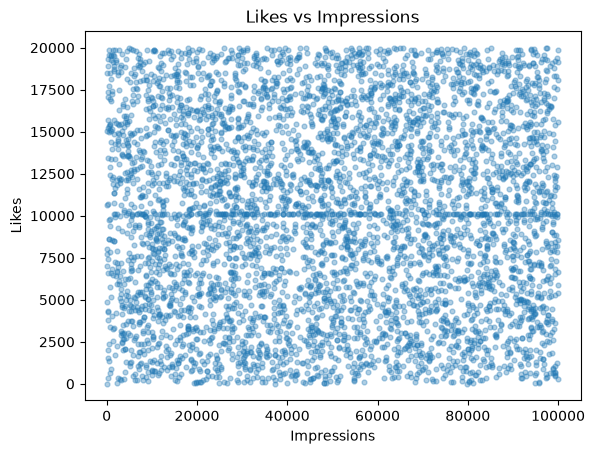

In [ ]:
# 1 Scatter
plt.scatter(df["impressions"], df["likes"], alpha=.35, s=12)
plt.xlabel("Impressions"); plt.ylabel("Likes"); plt.title("Likes vs Impressions"); plt.show()

### Insight:

The scatter plot shows the relationship between impressions and likes. Posts with higher impressions may receive more likes. However, some posts with high impressions may still receive fewer likes, indicating that reach does not always guarantee engagement.

##  2.Line Chart- Daily Engagement Trend

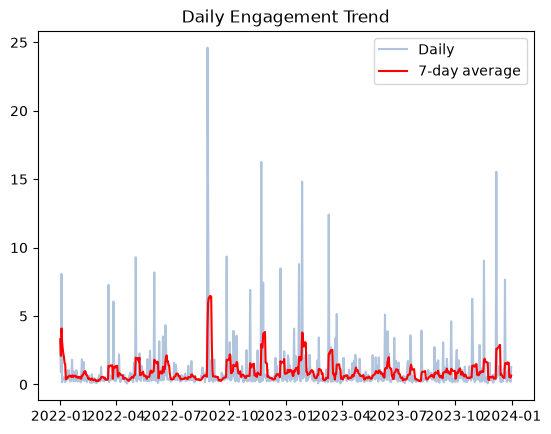

In [ ]:
# 2 Line - daily engagement trend
daily = df.set_index("date")["engagement_rate"].resample("D").mean().dropna()
plt.plot(daily.index, daily.values, color="lightsteelblue", label="Daily")
plt.plot(daily.index, daily.rolling(7, min_periods=1).mean(), color="red", label="7-day average")
plt.legend(); plt.title("Daily Engagement Trend"); plt.show()

### Insight:

The line chart shows how engagement changes over time. Peaks indicate days with higher engagement, while lower points indicate days with reduced engagement. This helps identify dates with better content performance.



## 3.Bar Chart- Posts by Category

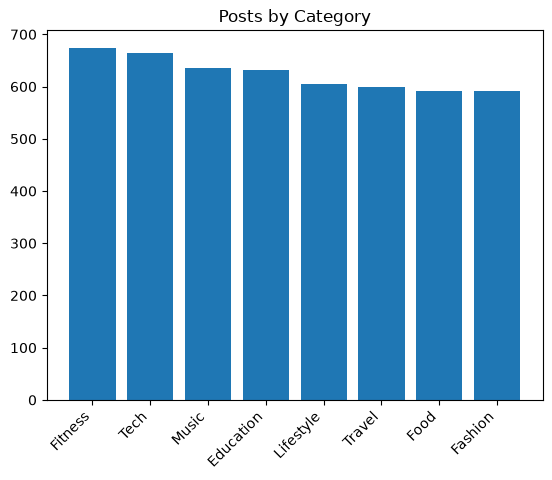

In [ ]:
# 3 Bar - posts by category
c = df["category"].value_counts()
plt.bar(c.index, c.values); plt.xticks(rotation=45, ha="right"); plt.title("Posts by Category"); plt.show()

### Insight:

The bar chart compares the number of posts across different content categories. Categories with higher post counts are more frequently used, while categories with fewer posts may represent less popular content types.

## 4.Pie Chart-Gender Distribution

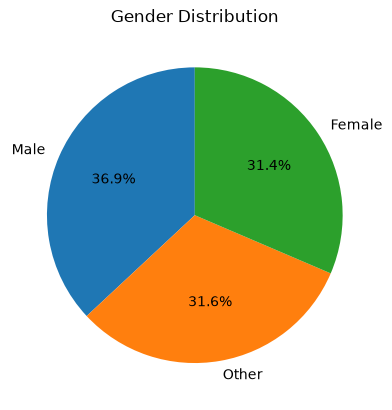

In [ ]:
# 4 Pie - gender
g = df["gender"].value_counts()
plt.pie(g.values, labels=g.index, autopct="%1.1f%%", startangle=90); plt.title("Gender Distribution"); plt.show()

### Insight:

The pie chart represents the distribution of users by gender. It helps understand the demographic composition of the dataset and identify the largest gender group.

## 5.Box Plot-Engagement Rate

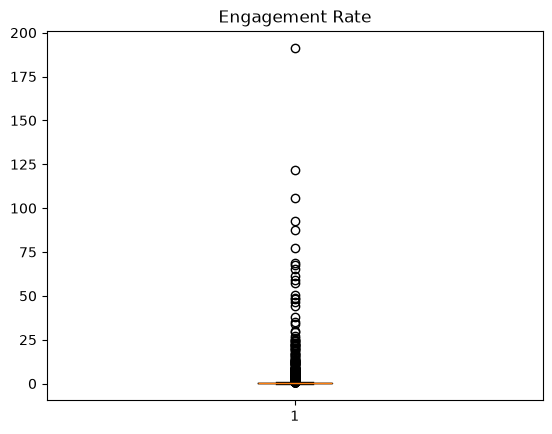

In [ ]:
# 6 Box - engagement rate
plt.boxplot(df["engagement_rate"]); plt.title("Engagement Rate"); plt.show()

### Insight:

The box plot displays the distribution of engagement rates and identifies outliers. The presence of outliers indicates that some posts have unusually high or low engagement rates compared with the majority of posts.

## 6.Count Plot-Post Type

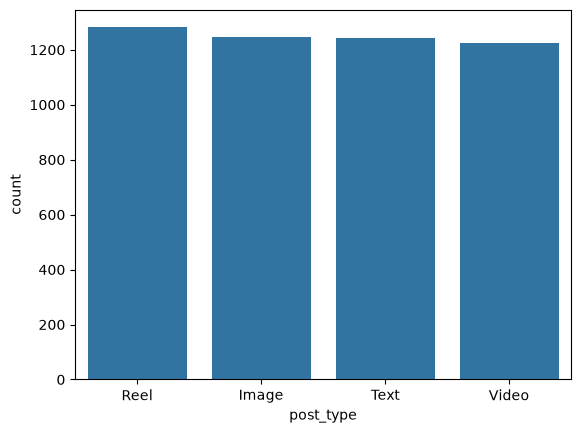

In [ ]:
# 7 Count plot
sns.countplot(data=df, x="post_type", order=df["post_type"].value_counts().index); plt.show()

###  Insight:

The count plot compares the frequency of different post types. It helps identify which post types are most commonly published and which are less frequently used.

## 8. Bar Plot-Average Likes by Category

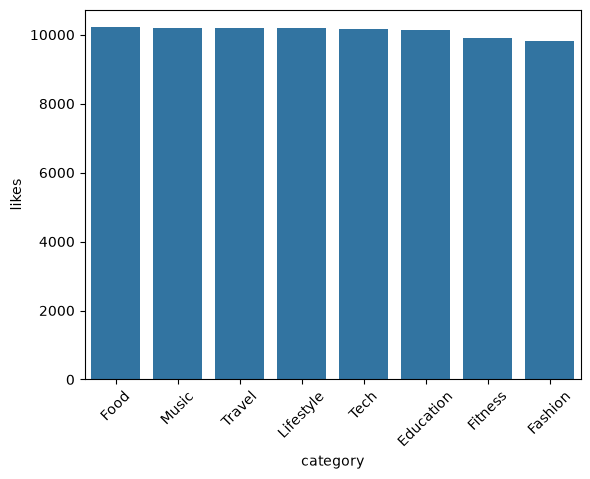

In [ ]:
# 8 Bar plot - avg likes by category
order = df.groupby("category")["likes"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="category", y="likes", order=order,
             errorbar=None); plt.xticks(rotation=45); plt.show()

### Insight:

The bar plot compares average likes across content categories. Categories with higher average likes demonstrate stronger audience interest in terms of likes, while lower values indicate comparatively weaker performance.

##  9.Violin Plot-Followers vs Sentiment

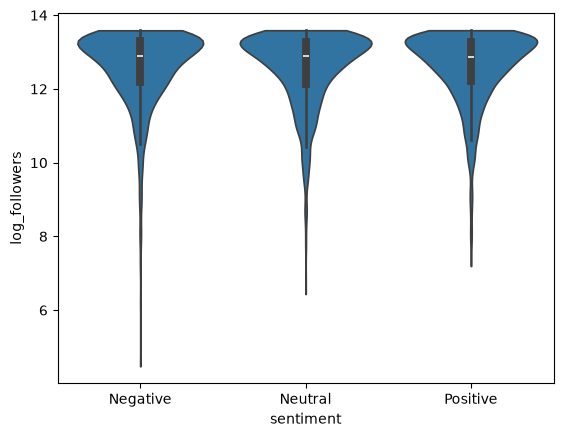

In [ ]:
# 9 Violin - followers vs sentiment (log scale because followers are skewed)
sns.violinplot(data=df, x="sentiment", y="log_followers", order=["Negative","Neutral","Positive"],
                cut=0); plt.show()

### Insight:

The violin plot shows the distribution of followers across different sentiment groups. Differences in the shape and spread of the distributions indicate variations in follower counts among positive, neutral, and negative sentiment posts.


## 10. Pair Plot-Numeric Features

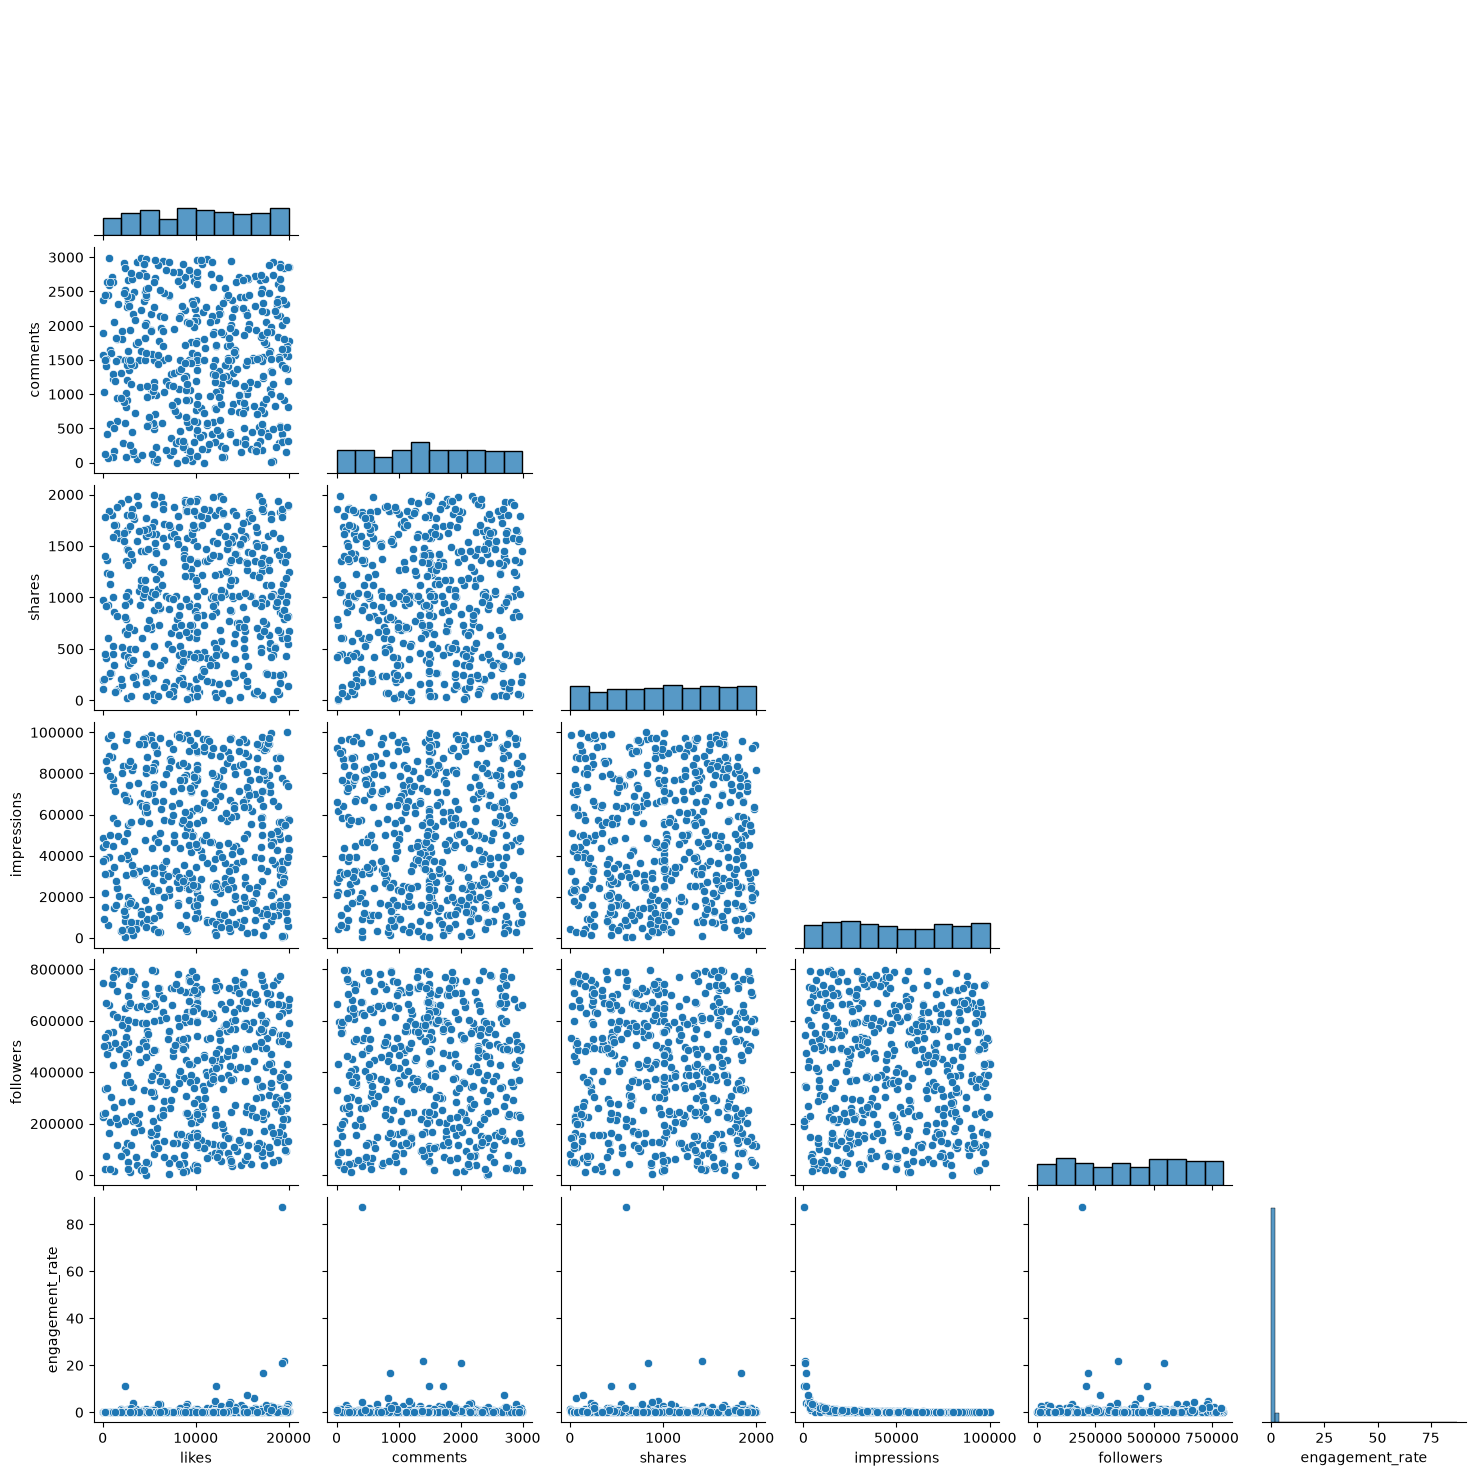

In [ ]:
# 10 Pair plot
PAIR = ["likes","comments","shares","impressions","followers","engagement_rate"]
sns.pairplot(df.sample(500, random_state=1)[PAIR], corner=True); plt.show()

### Insight:

The pair plot provides a visual comparison of multiple numerical features, including likes, comments, shares, impressions, engagement rate, and followers. The scatter plots show how individual observations are distributed between pairs of variables, while the diagonal plots display the distribution of each variable. It helps identify visible patterns, clusters, unusual observations, and possible relationships between engagement metrics


## 11.Heatmap-Correlation Matrix

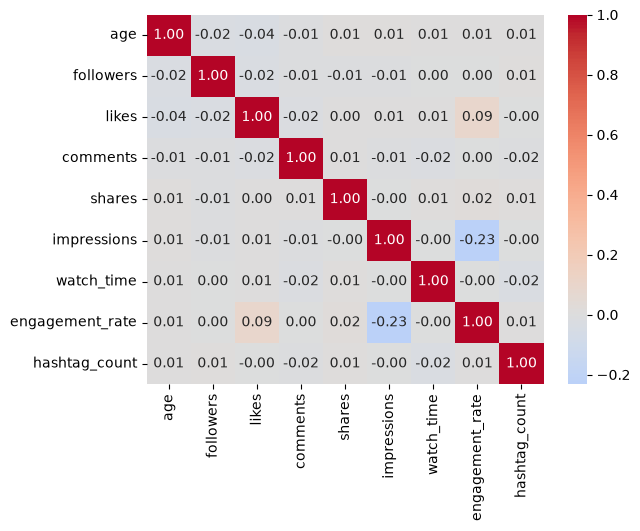

In [ ]:
# 11 Heatmap
sns.heatmap(df[NUMS].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.show()

### Insight:

The correlation heatmap represents relationships between numerical variables. Positive correlations indicate that variables tend to increase together, while negative correlations indicate an inverse relationship. Strong correlations can help identify important relationships between social media engagement metrics.


## 12.Swarm Plot-Engagement vs Device

c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 54.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 52.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 55.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 62.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarni

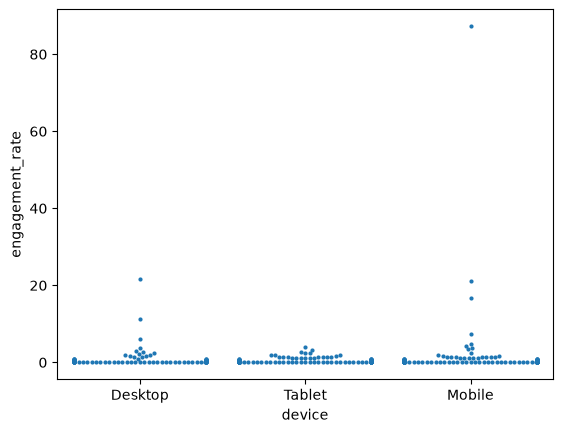

In [ ]:
# 12 Swarm (sample: swarm plots are slow on 5,000 points)
sns.swarmplot(data=df.sample(400, random_state=1), x="device",
               y="engagement_rate", size=3); plt.show()

### Insight:

The swarm plot displays individual engagement observations across device types. It helps compare engagement distributions and identify differences in engagement patterns among users accessing social media through different devices.

## 13.Interactive Plotly Chart

In [ ]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "vscode"      # for VS Code
# if blank, try:  pio.renderers.default = "browser"

In [ ]:
daily = df.set_index("date")["engagement_rate"].resample("D").mean().dropna()

In [ ]:
STAT_COLS = ["likes", "comments", "shares", "watch_time", "engagement_rate", "followers"]
rows = {}
for c in STAT_COLS:
    s = df[c]
    rows[c] = {"mean": s.mean(), "median": s.median(), "mode": s.mode().iloc[0],
               "std_dev": s.std(), "variance": s.var(),
               "P25": s.quantile(.25), "P50": s.quantile(.50), "P75": s.quantile(.75),
               "P90": s.quantile(.90), "P95": s.quantile(.95),
               "skewness": s.skew(), "kurtosis": s.kurt()}
stats_df = pd.DataFrame(rows).T
stats_df

,mean,median,mode,std_dev,variance,P25,P50,P75,P90,P95,skewness,kurtosis
likes,10104.577940,10105.500000,10105.500000,5703.065853,3.252496e+07,5224.500000,10105.500000,14960.000000,18006.000000,19093.500000,-0.007126,-1.150992
comments,1502.158085,1497.000000,1497.000000,856.843262,7.341804e+05,791.000000,1497.000000,2236.000000,2696.000000,2861.000000,0.003037,-1.145825
shares,1003.605290,1012.000000,1012.000000,570.492100,3.254612e+05,512.000000,1012.000000,1483.000000,1796.000000,1901.500000,-0.015166,-1.145677
watch_time,4015.716490,4034.000000,916.000000,2306.931416,5.321933e+06,2023.500000,4034.000000,6021.000000,7212.000000,7576.500000,-0.017776,-1.195486
engagement_rate,0.965062,0.253948,0.006363,5.322727,2.833142e+01,0.145777,0.253948,0.504695,1.200952,2.331812,18.764987,482.142768
followers,393721.506111,389027.000000,497502.000000,230943.984018,5.333512e+10,194464.000000,389027.000000,589759.500000,717748.000000,760573.500000,0.040824,-1.189737


In [ ]:
%pip install plotly nbformat
import plotly.express as px


   ------ --------------------------------- 1/6 [fastjsonschema]
   ------ --------------------------------- 1/6 [fastjsonschema]
   ------------- -------------------------- 2/6 [referencing]
   ------------- -------------------------- 2/6 [referencing]
   -------------------- ------------------- 3/6 [jsonschema-specifications]
   -------------------------- ------------- 4/6 [jsonschema]
   -------------------------- ------------- 4/6 [jsonschema]
   -------------------------- ------------- 4/6 [jsonschema]
   -------------------------- ------------- 4/6 [jsonschema]
   -------------------------- ------------- 4/6 [jsonschema]
   -------------------------- ------------- 4/6 [jsonschema]
   -------------------------- ------------- 4/6 [jsonschema]
   -------------------------- ------------- 4/6 [jsonschema]
   -------------------------- ------------- 4/6 [jsonschema]
   --------------------------------- ------ 5/6 [nbformat]
   --------------------------------- ------ 5/6 [nbformat]
  


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
%pip install --upgrade nbformat plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import plotly.io as pio
pio.renderers.default = "browser"

In [ ]:
d = daily.reset_index(); d.columns = ["date", "engagement_rate"]
px.line(d, x="date", y="engagement_rate", title="Daily Engagement Rate").show()

In [ ]:
ce = df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False).reset_index()
px.bar(ce, x="country", y="engagement_rate", color="engagement_rate", title="Avg Engagement Rate by Country").show()

In [ ]:
df = df.loc[:, ~df.columns.duplicated()]      # remove duplicate columns
df = df.rename(columns={"hashtagcount": "hashtag_count"})
print(df.columns[df.columns.duplicated()].tolist())   # should print []

[]


In [ ]:
import plotly.io as pio
pio.renderers.default = "browser"

In [ ]:
px.scatter(df.sample(1500, random_state=1), x="impressions", y="likes", size="followers",
           color="post_type", hover_data=["country","sentiment"], size_max=28, opacity=.6).show()

ValueError: Value of 'x' is not the name of a column in 'data_frame'. Expected one of ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate'] but received: impressions

In [ ]:
px.box(df, x="sentiment", y="engagement_rate", color="sentiment").show()

In [ ]:
r = df["impressions"].corr(df["likes"])
print("Correlation (r) =", round(r, 3))

Correlation (r) = 0.008


In [ ]:
q1, q3 = df["engagement_rate"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
n_out = (df["engagement_rate"] > upper).sum()
print(f"Upper fence: {upper:.2f} | Outliers: {n_out} ({n_out/len(df):.1%} of posts)")
print("Skewness:", round(df["engagement_rate"].skew(), 2))

Upper fence: 1.04 | Outliers: 576 (11.5% of posts)
Skewness: 18.76


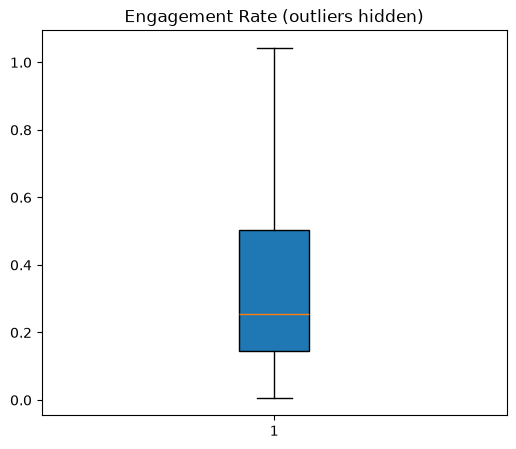

In [ ]:
# Option B: zoom in on the typical posts (hides the dots)
plt.figure(figsize=(6, 5))
plt.boxplot(df["engagement_rate"], showfliers=False, patch_artist=True)
plt.title("Engagement Rate (outliers hidden)")
plt.show()

## Final Insights

### Content Performance

In [ ]:
by_type = df.groupby("post_type").agg(**AGG).sort_values("avg_engagement_rate", ascending=False)
print(by_type.index[0], by_type["avg_score"].idxmax())   # best by rate, best by weighted score

Video Image


In [ ]:
by_cat = df.groupby("category").agg(**AGG).sort_values("avg_engagement_rate", ascending=False)
print(by_cat.index[0], by_cat["avg_likes"].idxmax())

Food Food


In [ ]:
df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False).head(3)

country
Brazil       1.540704
Australia    1.324339
France       1.148539
Name: engagement_rate, dtype: float64

### User Trends

In [ ]:
df["age_group"] = pd.cut(df["age"], [12,17,24,34,44,54,100], labels=["13-17","18-24","25-34","35-44","45-54","55+"])
print(df.groupby("age_group", observed=True)["engagement_rate"].mean())
print(df["age"].corr(df["engagement_rate"]))     # |r| < 0.1 means practically no effect

age_group
13-17    0.864270
18-24    1.036141
25-34    0.811187
35-44    0.957581
45-54    1.204305
55+      0.899329
Name: engagement_rate, dtype: float64
0.007953709839793498


In [ ]:
cols = ["followers","likes","comments","shares","impressions","watch_time","engagement_rate"]
v = df.groupby("verified")[cols].mean().T
v["% difference"] = (v[True] / v[False] - 1) * 100
v

verified,False,True,% difference
followers,394966.337472,382049.594595,-3.270340
likes,10137.417073,9796.668399,-3.361297
comments,1505.799778,1468.012474,-2.509451
shares,1002.275831,1016.070686,1.376353
impressions,49942.670510,50621.735967,1.359690
watch_time,4007.277827,4094.839917,2.185077
engagement_rate,0.955185,1.057664,10.728635


### Behavioural Insights

In [ ]:
df["hour_of_day"] = df["date"].dt.hour            # or your hour column
df["time_of_day"] = pd.cut(df["hour_of_day"], [-1,5,11,16,20,23],
    labels=["Night","Morning","Afternoon","Evening","Late Night"])
df.groupby("time_of_day", observed=True)["impressions"].mean().sort_values(ascending=False)

time_of_day
Night    50008.114406
Name: impressions, dtype: float64

In [ ]:
df.groupby("device")["watch_time"].agg(["mean","median","count"]).sort_values("mean", ascending=False)

,mean,median,count
device,,,
Mobile,4087.295900,4110.0,1683
Tablet,3985.062916,4077.0,1653
Desktop,3973.542598,3921.0,1655


### Sentiment Analysis

In [ ]:
sent = df.groupby("sentiment").agg(**AGG)
print(sent["avg_engagement_rate"].idxmax(), sent["avg_score"].idxmax())

Negative Negative


In [ ]:
m = ["likes","comments","shares","impressions","engagement_rate","watch_time"]
overall = df[m].mean()
for s in ["Negative","Neutral"]:
    print(s, ((df.loc[df["sentiment"]==s, m].mean() / overall - 1) * 100).round(1).to_dict())
    sub = df[df["sentiment"]==s]
    print("comments per like:", sub["comments"].sum()/sub["likes"].sum())

Negative {'likes': 0.9, 'comments': 0.8, 'shares': 0.3, 'impressions': 0.3, 'engagement_rate': 7.8, 'watch_time': 0.9}
comments per like: 0.14848104432569367
Neutral {'likes': -1.8, 'comments': 1.8, 'shares': -0.6, 'impressions': -1.0, 'engagement_rate': 2.8, 'watch_time': 0.4}
comments per like: 0.1540938733748455


## Social Media Engagement Analytics – Project Summary

### Objective

To analyze social media engagement data and understand user behavior, content performance, and engagement patterns using Python.

Tools Used

Python, Pandas, NumPy, Matplotlib, Seaborn, Plotly, Jupyter Notebook.

### Data Analysis

- Dataset structure and data types were examined.
- Missing values and duplicate records were checked.
- Data cleaning and transformation were performed.
- Descriptive statistics were calculated.
- Groupby analysis and correlation analysis were conducted.
- Multiple visualizations were created to explore engagement metrics.

### Key Areas of Analysis

- Likes vs impressions
- Daily engagement trends
- Posts by category and post type
- Gender and age distribution
- Engagement rate distribution
- Average likes by category
- Followers by sentiment
- Correlation between numerical features
- Engagement across device types

### Conclusion

This project demonstrates the application of Python data analysis techniques to social media engagement data. The analysis provides a foundation for understanding audience behavior, evaluating content performance, and supporting data-driven decisions.





## Conclusion on the Visualization

The histogram, pie and count plots describe the audience and the content mix: the typical age is [median age], the largest gender group is [group], and the most used post type is [type]. These show volume, not performance.The box plot, pair plot and violin show whether likes, shares and followers are skewed. If the mean is well above the median, a few viral posts drive the averages, so use the median for a typical post.
The scatter, heatmap and bubble chart show that [strongest pair, for example comments and likes] move together most (r = [value]). Check whether engagement rate depends on reach or followers; if r is close to 0, a bigger audience does not mean a more engaged one.
The bar plots, swarm plot and Plotly bar and box charts rank [post type], [category], [country], [device] and [sentiment]. Report the size of each gap: a difference under about 5% is a tendency, not a firm winner.
The line charts show whether daily engagement is [rising, falling or stable] and which day peaked.